# Hyperspectral peak maps with batchfit

Each pixel of this **512 × 512** image contains 129 spectral samples. We generate smoothly varying peak center, Lorentzian **HWHM** (half-width at half maximum), and peak-height amplitude, add fixed-seed Gaussian noise, and inject twelve labeled defects. Every pixel is fitted, including defects; no ground-truth values are used as initial guesses.

From the repository root, install the pinned demo dependencies with `uv pip install -e '.[demo]'`, then launch Jupyter from `.venv` (see `examples/README.md` for a project-local, loopback-only command). Select the Python kernel in that environment and **Restart Kernel → Run All**. `python tools/check_demo.py` verifies this notebook headlessly. No data download is required.

In [1]:
from pathlib import Path
import json
import os
import sys
from time import perf_counter

ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').is_file(), 'Start Jupyter from this repository or examples/'
assert Path(sys.prefix).resolve() == ROOT / '.venv', 'Select the project .venv Python kernel'
for name in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ[name] = '1'
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.agent-local/cache/matplotlib'))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import batchfit
%matplotlib inline
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Python:', sys.executable)
print('batchfit:', batchfit.__version__, '| Metal available:', batchfit.metal_available())

Python: /Users/mk-rune/test_projects/13-batchfit/.venv/bin/python
batchfit: 0.1.0 | Metal available: True


In [2]:
H, W, M = 512, 512, 129
DEVICE = 'auto'  # 'cpu' or 'metal' also work; float32 auto uses available Metal.
CHUNK_PIXELS = 8192
NOISE_STD = np.float32(0.02)
SEED = 20261115
REAL_DATA_DIR = None  # Set to ROOT / 'data/my_scan' to run the real-data section.

## 1. Make a cube with spatially varying peaks

The spectral coordinate is in arbitrary calibrated units on [−5, 5]. The model is `amplitude / (1 + ((x − center) / HWHM)**2)` with **no baseline**. The cube is C-contiguous float32, with spectral samples on the **last axis**. Generation uses bounded pixel blocks instead of allocating a second clean cube.

In [3]:
x = np.linspace(-5, 5, M, dtype=np.float32)
row, col = np.meshgrid(np.linspace(0, 1, H, dtype=np.float32),
                       np.linspace(0, 1, W, dtype=np.float32), indexing='ij')
true_center = (0.75*np.sin(2*np.pi*row)*np.cos(2*np.pi*col) + 0.2*(col-0.5)).astype(np.float32)
true_width = (0.65 + 0.18*np.cos(2*np.pi*row)*np.sin(2*np.pi*col)).astype(np.float32)
true_amplitude = (2.0 + 0.35*np.sin(np.pi*row)*np.cos(2*np.pi*col)).astype(np.float32)
truth = np.stack((true_amplitude, true_center, true_width), axis=-1)
cube = np.empty((H, W, M), dtype=np.float32)
flat_cube = cube.reshape(-1, M)
flat_truth = truth.reshape(-1, 3)
random = np.random.default_rng(SEED)
for first in range(0, H*W, CHUNK_PIXELS):
    last = min(H*W, first+CHUNK_PIXELS)
    amplitude, center, width = flat_truth[first:last].T
    z = (x[None, :] - center[:, None]) / width[:, None]
    signal = amplitude[:, None] / (1 + z*z)
    signal += NOISE_STD * random.standard_normal(signal.shape, dtype=np.float32)
    flat_cube[first:last] = signal

defective_pixels = [(30, 40), (80, 120), (160, 420), (240, 240),
                    (350, 80), (460, 460), (100, 360), (200, 60),
                    (300, 400), (410, 260), (500, 20), (32, 500)]
defect_mask = np.zeros((H, W), dtype=bool)
for index, (r, c) in enumerate(defective_pixels):
    defect_mask[r, c] = True
    if index % 3 == 0:
        cube[r, c, :] = np.nan  # Missing acquisition.
    elif index % 3 == 1:
        cube[r, c, M//2] = np.inf  # Nonfinite detector spike.
    else:
        cube[r, c, :] = 0  # Dead, flat spectrum.
assert cube.shape == (512, 512, 129) and cube.flags.c_contiguous
assert np.shares_memory(flat_cube, cube)
print(f'{H*W:,} pixels; cube={cube.shape}, {cube.nbytes/2**20:.1f} MiB; defects={defect_mask.sum()}')

262,144 pixels; cube=(512, 512, 129), 129.0 MiB; defects=12


## 2. Fit every pixel without truth-based seeds

Flattening `(H,W,M)` to `(H*W,M)` is a view, so pixel order remains `row*W + column`. We fit blocks and retain only small output maps. `p0=None` invokes batchfit's data-only initial guesses; width and center bounds are derived from the x-axis, not the truth. NaN/Inf/flat pixels are submitted normally and remain explicit failures. With automatic guesses, flat spectra can fail initialization as `invalid_input`; a converged status is never fabricated.

In [4]:
def fit_cube(x_axis, spectra, device='auto', chunk_pixels=8192):
    if x_axis.ndim != 1 or spectra.ndim != 3 or spectra.shape[-1] != x_axis.size:
        raise ValueError('Expected x[M] and cube[H,W,M] with matching M')
    if min(spectra.shape) <= 0 or x_axis.size < 4 or chunk_pixels <= 0:
        raise ValueError('Nonempty spatial dimensions, M>=4 and positive chunks are required')
    if x_axis.dtype not in (np.dtype('float32'), np.dtype('float64')) or spectra.dtype not in (np.dtype('float32'), np.dtype('float64')):
        raise TypeError('Use native float32 or float64 arrays; convert deliberately before fitting')
    if not spectra.flags.c_contiguous:
        raise ValueError('Store cube C-contiguously with spectral samples last')
    if not np.all(np.isfinite(x_axis)) or not np.all(np.diff(x_axis) > 0):
        raise ValueError('The calibrated x-axis must be finite and strictly increasing')
    height, width, points = spectra.shape
    rows = spectra.reshape(-1, points)
    assert np.shares_memory(rows, spectra)
    common = np.result_type(x_axis.dtype, spectra.dtype)
    dtype = np.float32 if device == 'metal' or common == np.dtype('float32') else np.float64
    params = np.empty((height*width, 3), dtype=dtype)
    status = np.empty(height*width, dtype=np.int32)
    iterations = np.empty(height*width, dtype=np.uint32)
    chi2 = np.empty(height*width, dtype=dtype)
    bounds = ([0, float(x_axis[0]), float(np.min(np.diff(x_axis)))/4],
              [np.inf, float(x_axis[-1]), float(x_axis[-1]-x_axis[0])])
    submitted = 0
    for first in range(0, height*width, chunk_pixels):
        last = min(height*width, first+chunk_pixels)
        fitted = batchfit.fit(x_axis, rows[first:last], model='lorentzian',
                              p0=None, bounds=bounds, device=device)
        params[first:last], status[first:last] = fitted.params, fitted.status
        iterations[first:last], chi2[first:last] = fitted.iterations, fitted.chi2
        submitted += last-first
    assert submitted == height*width
    return {'params': params.reshape(height, width, 3), 'status': status.reshape(height, width),
            'iterations': iterations.reshape(height, width), 'chi2': chi2.reshape(height, width),
            'submitted': submitted}

In [5]:
started = perf_counter()
maps = fit_cube(x, cube, DEVICE, CHUNK_PIXELS)
fit_seconds = perf_counter()-started
valid = maps['status'] == int(batchfit.FitStatus.converged)
healthy = ~defect_mask
status_counts = {state.name: int(np.count_nonzero(maps['status'] == int(state))) for state in batchfit.FitStatus}
backend = 'metal' if DEVICE == 'metal' or (DEVICE == 'auto' and batchfit.metal_available()) else 'cpu'
print(f'Backend: {backend}; submitted {maps["submitted"]:,}/{H*W:,} pixels in {fit_seconds:.3f} s (includes initialization and packing)')
print('Status counts:', status_counts)
print('Healthy convergence:', f'{np.count_nonzero(valid & healthy)}/{np.count_nonzero(healthy)}')
print('Defects flagged:', f'{np.count_nonzero(~valid & defect_mask)}/{defect_mask.sum()}')
assert maps['submitted'] == H*W
assert np.count_nonzero(valid & healthy)/np.count_nonzero(healthy) >= 0.999
assert np.all(~valid[defect_mask]), 'Every deliberately nonfinite/flat pixel should be flagged'

Backend: metal; submitted 262,144/262,144 pixels in 1.839 s (includes initialization and packing)
Status counts: {'converged': 262132, 'max_iterations': 0, 'singular_matrix': 0, 'invalid_input': 12, 'degenerate_data': 0, 'unresolved_peak': 0}
Healthy convergence: 262132/262132
Defects flagged: 12/12


## 3. Fitted parameter, objective and status maps

Black in parameter/objective maps means **not converged**, not zero. Red rings mark injected defects; the categorical status panel retains every pixel. `chi2` is the unweighted residual sum of squares, not already reduced by degrees of freedom. HWHM is used throughout (FWHM = 2 × HWHM).

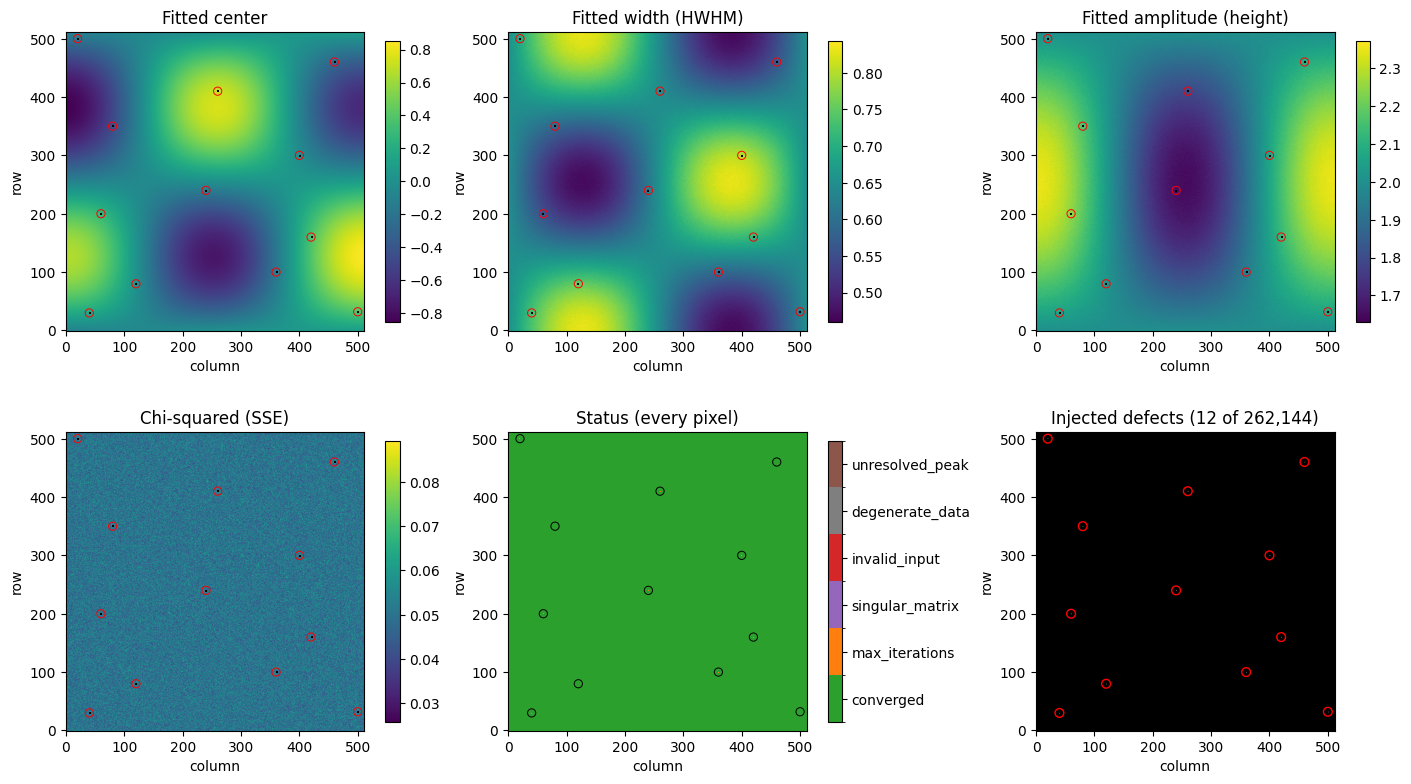

In [6]:
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad('black')
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
panels = [('Fitted center', maps['params'][..., 1]), ('Fitted width (HWHM)', maps['params'][..., 2]),
          ('Fitted amplitude (height)', maps['params'][..., 0]), ('Chi-squared (SSE)', maps['chi2'])]
bad_r, bad_c = np.nonzero(defect_mask)
for ax, (title, values) in zip(axes.flat, panels):
    image = ax.imshow(np.ma.masked_where(~valid, values), origin='lower', cmap=cmap)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, shrink=0.8)
    ax.scatter(bad_c, bad_r, s=35, facecolors='none', edgecolors='red', linewidths=0.7)
states = list(batchfit.FitStatus)
status_cmap = ListedColormap(['#2ca02c', '#ff7f0e', '#9467bd', '#d62728', '#7f7f7f', '#8c564b'])
image = axes[1, 1].imshow(maps['status'], origin='lower', cmap=status_cmap,
                          norm=BoundaryNorm(np.arange(-0.5, len(states)+0.5), len(states)))
axes[1, 1].set_title('Status (every pixel)')
bar = fig.colorbar(image, ax=axes[1, 1], ticks=np.arange(len(states)), shrink=0.8)
bar.ax.set_yticklabels([state.name for state in states])
axes[1, 1].scatter(bad_c, bad_r, s=35, facecolors='none', edgecolors='black', linewidths=0.7)
axes[1, 2].imshow(defect_mask, origin='lower', cmap='gray', vmin=0, vmax=1)
axes[1, 2].scatter(bad_c, bad_r, s=40, facecolors='none', edgecolors='red')
axes[1, 2].set_title('Injected defects (12 of 262,144)')
for ax in axes.flat:
    ax.set_xlabel('column'); ax.set_ylabel('row')
plt.show()
plt.close(fig)

## 4. Ground truth and signed error maps

Error = fitted − true. Failed pixels are masked, but healthy-pixel convergence is checked separately so a small RMSE cannot hide dropped fits. Ground truth is used **only** for generation/validation, never for fitting.

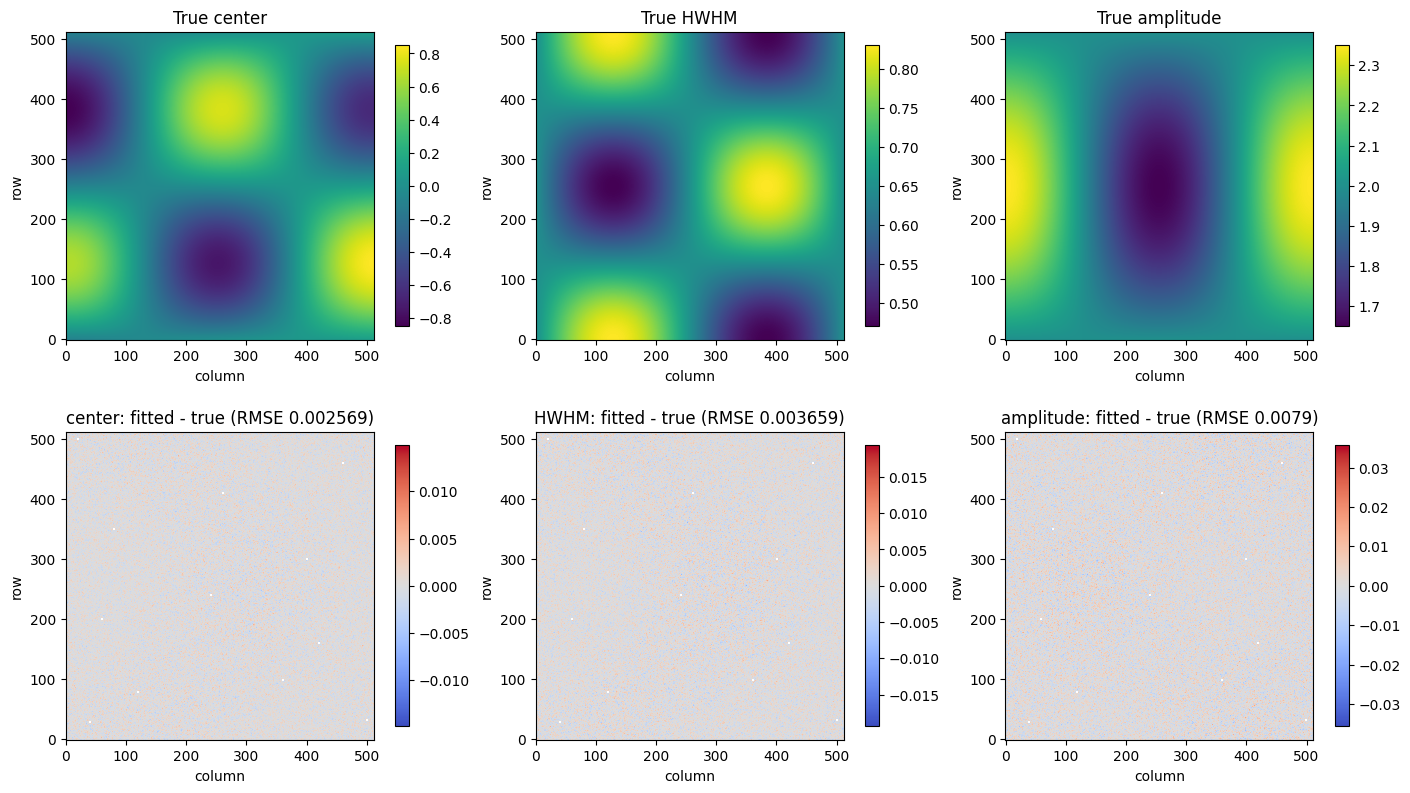

DEMO_SUMMARY {"backend": "metal", "defects": 12, "errors": {"HWHM": {"max_abs": 0.019358813762664795, "rmse": 0.0036590748976915383}, "amplitude": {"max_abs": 0.03567075729370117, "rmse": 0.007900291556940317}, "center": {"max_abs": 0.014880061149597168, "rmse": 0.0025687090502836863}}, "fit_seconds": 1.8387720409999997, "flagged_defects": 12, "healthy_converged": 262132, "healthy_pixels": 262132, "shape": [512, 512, 129], "status_counts": {"converged": 262132, "degenerate_data": 0, "invalid_input": 12, "max_iterations": 0, "singular_matrix": 0, "unresolved_peak": 0}, "submitted": 262144}


In [7]:
errors = maps['params'] - truth
metrics = {}
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for column, (name, parameter) in enumerate([('center', 1), ('HWHM', 2), ('amplitude', 0)]):
    selected = errors[..., parameter][valid & healthy]
    metrics[name] = {'rmse': float(np.sqrt(np.mean(selected.astype(float)**2))),
                     'max_abs': float(np.max(np.abs(selected)))}
    true_image = axes[0, column].imshow(truth[..., parameter], origin='lower', cmap='viridis')
    axes[0, column].set_title('True ' + name)
    fig.colorbar(true_image, ax=axes[0, column], shrink=0.8)
    limit = max(float(np.max(np.abs(selected))), 1e-8)
    error_image = axes[1, column].imshow(np.ma.masked_where(~valid, errors[..., parameter]),
                                               origin='lower', cmap='coolwarm', vmin=-limit, vmax=limit)
    axes[1, column].set_title(f'{name}: fitted - true (RMSE {metrics[name]["rmse"]:.4g})')
    fig.colorbar(error_image, ax=axes[1, column], shrink=0.8)
for ax in axes.flat:
    ax.set_xlabel('column'); ax.set_ylabel('row')
plt.show()
plt.close(fig)
assert metrics['center']['rmse'] < 0.01
assert metrics['HWHM']['rmse'] < 0.015
assert metrics['amplitude']['rmse'] < 0.03
demo_summary = {'shape': list(cube.shape), 'backend': backend, 'submitted': maps['submitted'],
                'healthy_pixels': int(healthy.sum()), 'healthy_converged': int((valid & healthy).sum()),
                'defects': int(defect_mask.sum()), 'flagged_defects': int((~valid & defect_mask).sum()),
                'fit_seconds': fit_seconds, 'status_counts': status_counts, 'errors': metrics}
print('DEMO_SUMMARY ' + json.dumps(demo_summary, sort_keys=True))

## 5. Load your real data: `cube.npy[H,W,M]` + `x.npy[M]`

Put two ordinary NumPy files in a directory such as `data/my_scan/`:

- **`cube.npy`**: a C-contiguous float32 or float64 array, shape `(height, width, spectral_samples)`. The last axis is intensity at the shared calibrated x positions.
- **`x.npy`**: a finite, strictly increasing float32/float64 vector, shape `(spectral_samples,)`, in your physical coordinate units (for example wavelength, energy or Raman shift). Every pixel must share this grid.

Set `REAL_DATA_DIR = ROOT / 'data/my_scan'` in the parameters cell and rerun this section. `allow_pickle=False` rejects object-file payloads. Read-only memory mapping keeps the input file off the Python heap; pixel chunks and output maps bound working memory. Nonfinite pixel values are **not** silently dropped or replaced.

This example assumes one positive Lorentzian emission peak **without a baseline**. Do not apply it unchanged to arbitrary reflectance/absorption or baseline-contaminated spectra. Calibrate/preprocess deliberately, choose a suitable model and inspect status/residuals. Width and center have x-axis units; amplitude has intensity units; chi2 has squared-intensity units. float64 + `device='auto'` stays on CPU; explicit Metal uses float32. See `NUMERICS.md` before converting large-offset/narrow-range axes to float32. File dtype conversion should be explicit, not an accidental full-cube copy.

In [8]:
if REAL_DATA_DIR is not None:
    real_dir = Path(REAL_DATA_DIR)
    real_x = np.load(real_dir / 'x.npy', allow_pickle=False)
    real_cube = np.load(real_dir / 'cube.npy', allow_pickle=False, mmap_mode='r')
    real_maps = fit_cube(real_x, real_cube, DEVICE, CHUNK_PIXELS)
    print('Real-data output maps:', real_maps['params'].shape, real_maps['chi2'].shape)
    print('Real-data status counts:', {state.name: int((real_maps['status'] == int(state)).sum()) for state in batchfit.FitStatus})
    # Reuse the map plotting cells with real_maps; truth/error maps do not exist for a real scan.
else:
    print('Real-data loading is ready. Set REAL_DATA_DIR to a directory containing x.npy and cube.npy.')

Real-data loading is ready. Set REAL_DATA_DIR to a directory containing x.npy and cube.npy.
